In [1]:
#imports
%load_ext autoreload
%autoreload 2
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

sys.path.insert(0, "../pipeline")   # the code is in the pipeline folder
from config import SESSION_PARTICIPANT_CSV
from preprocess import GOAL_EVENTS, read_events, read_frames, read_hand_filled_csv   # only reads the files, changes nothing

## The raw data

**session** = one recording (pre or post can have several) · **task** = one of the 8 exercises · **trial** = one repetition of a task · **frame** = one snapshot of the 15 body points (16 to 43 per second, depending on the session).

One session = 3 files with the same name `upper_limb_<date>_<time>`:
- `.events.jsonl`: what happened and when (task start, trial start, target reached, trial end, ...)
- `.frames.csv`: one row per frame, 15 body points × (x, y, z, confidence)
- `.meta.json`: the settings of the session

# MAM: the raw data of one task

The **raw recording, with no processing**: nothing is filtered, interpolated, cut, turned or removed. This is a first look at the data, before deciding what to do with it.

For one whole task with one arm (all its trials, and what happens between them): the wrist as saved by the camera system (x, y, z in room coordinates, in metres, y = height) and its speed, then the height of the shoulder point (stroke patients can compensate by lifting the shoulder).

**This notebook reads only the raw files and `data/session_participant.csv`** (which sessions are this patient's, pre or post, filled in by hand). It uses nothing from the pipeline.

## How the data is organised

**patient → session → task → trial → frame**

| Level | What it is | Column | Example |
|---|---|---|---|
| patient | one person | `participant_id` | MAM |
| session | one recording, normally one for pre and one for post. The column `visit` of `data/session_participant.csv` says which: 1 = pre, 2 = post treatment. It is not in the raw files: it was filled in by hand from the clinical team's dates | `session_id`, `visit` | `upper_limb_20260629_124026` (MAM, pre) |
| task | one of the 8 exercises, done with each arm, sometimes started again | `task_id`, `side` | task 1, right arm |
| trial | one repetition of the movement: 12 per task and arm, 30 for tasks 4 and 6 | `trial_index` | repetition 2 of 12 |
| frame | one snapshot of the body points | one row of `.frames.csv` | about 100 per trial |

**Exception:** if the recording was stopped and restarted, pre or post has several sessions. Pre of DBB: 2 sessions, of MAM: 3, of JFR: 4.

## What is available for this patient, MAM (CBD)
Pre and post, number of tasks and trials, then the trials per task, pre or post and arm. Normally 12 trials per task and arm, 30 for tasks 4 and 6; more = the task was started again.

In [2]:
PATIENT = "MAM"      # participant_id

# Which sessions are this patient's, and pre or post: written by hand in data/session_participant.csv.
sessions = read_hand_filled_csv(SESSION_PARTICIPANT_CSV)
sessions = sessions[sessions["participant_id"] == PATIENT]

# The trials, counted from the raw events: one trial_end per trial.
own = pd.DataFrame([{"visit": int(visit), "task_id": e["task_id"], "task_name": e["task_name"], "side": e["side"]}
                    for session_id, visit in zip(sessions["session_id"], sessions["visit"])
                    for e in read_events(session_id) if e["type"] == "trial_end"])

pre_post = " and ".join({1: "pre", 2: "post"}[v] for v in sorted(own["visit"].unique()))
print(f"{PATIENT}: {pre_post}, {own['task_id'].nunique()} tasks, {len(own)} trials")

session = own["visit"].map({1: "1 (pre)", 2: "2 (post)"}).rename("session")
pd.crosstab([own["task_id"], own["task_name"]], [session, own["side"]], margins=True, margins_name="all")

MAM: pre and post, 8 tasks, 535 trials


session                                        1 (pre)       2 (post)        \
side                                              left right     left right   
task_id task_name                                                             
1       Shoulder flexion with elbow extended        12    13       12    12   
2       Shoulder abduction with elbow extended      12    12       18    12   
3       Draw a 5 segment trajectory                 12    12       12    12   
4       Reaching different targets                  30    30       30    30   
5       Draw a circle                               12    12       12    12   
6       Horizontal reaching                         30    30       30    30   
7       Drinking test: reaching glass to mouth      12    12       12    12   
8       Index to nose                               12    12       12    12   
all                                                132   133      138   132   

session                                         all  
side                                                 
task_id task_name                                    
1       Shoulder flexion with elbow extended     49  
2       Shoulder abduction with elbow extended   54  
3       Draw a 5 segment trajectory              48  
4       Reaching different targets              120  
5       Draw a circle                            48  
6       Horizontal reaching                     120  
7       Drinking test: reaching glass to mouth   48  
8       Index to nose                            48  
all                                             535

## Which task

In [3]:
TASK_ID = 2         # task (1-8)
SESSION = 1            # 1 = pre, 2 = post
SIDE = "right"       # arm: "left" or "right"

## Read the raw files
The two raw files of the session: `events.jsonl` (what happened and when) and `frames.csv` (the body points). Only the frames between the start and the end of the task are kept. If the task was started several times with this arm, the start with the most trials is used (the last one if they are equal).

In [4]:
# Go through the sessions of this pre or post, one block of events per task start.
# The arm really used is in trial_end: the one written in task_start can be wrong.
most, n_starts = 0, 0
for candidate in sessions.loc[sessions["visit"] == str(SESSION), "session_id"]:
    events = read_events(candidate)
    starts = [i for i, e in enumerate(events) if e["type"] == "task_start"]
    for i, j in zip(starts, starts[1:] + [len(events)]):
        block = events[i:j]
        n_trials = sum(e["type"] == "trial_end" and e["side"] == SIDE for e in block)
        if block[0]["task_id"] == TASK_ID and n_trials > 0:
            n_starts += 1
            if n_trials >= most:   # the start with the most trials (the last one if equal)
                most, session_id, task_events = n_trials, candidate, block

start_time = task_events[0]["wall_time"]
end_time = next(e["wall_time"] for e in task_events if e["type"] == "task_end")

wrist = [f"{SIDE}_wrist_{axis}" for axis in "xyz"]
shoulder = [f"{SIDE}_shoulder_{axis}" for axis in "xyz"]
frames = read_frames(session_id, ["wall_time", "pose_t"] + wrist + shoulder)
frames = frames[frames["wall_time"].between(start_time, end_time)]
time = frames["wall_time"] - start_time                                         # same clock as the events
speed = np.linalg.norm(frames[wrist].diff(), axis=1) / frames["pose_t"].diff()  # camera clock: it is regular

print(f"{session_id}, task {TASK_ID} ({task_events[0]['task_name']}), {SIDE} arm: {most} trials, started {n_starts} time(s) with this arm")
print(f"{end_time - start_time:.1f} s, {len(frames)} frames, {1 / frames['pose_t'].diff().median():.1f} frames per second, "
      f"wrist missing in {frames[wrist[0]].isna().mean():.1%} of the frames")

upper_limb_20260629_124026, task 2 (Shoulder abduction with elbow extended), right arm: 12 trials, started 1 time(s) with this arm
40.0 s, 644 frames, 17.2 frames per second, wrist missing in 0.0% of the frames


## The time series
From top to bottom:
- the wrist in the 3 room directions, and its speed (distance between 2 consecutive frames / time between them);
- **shoulder height**: the height of the shoulder point, as recorded (stroke patients can compensate by lifting the shoulder).

**Same scale in every plot**, so patients, pre and post, tasks and arms can be compared: every panel in metres covers 1.2 m (wrist and shoulder height: always 0.4 to 1.6 m), and the speed goes from 0 to 5 m/s. The last panel shows the shoulder height again on a smaller scale, always 0.9 to 1.2 m, to see the shoulder lifting. If data falls outside these ranges, the cell prints how many frames.

 The vertical lines are the times written by the software in the events file. The number above each trial is its repetition number.

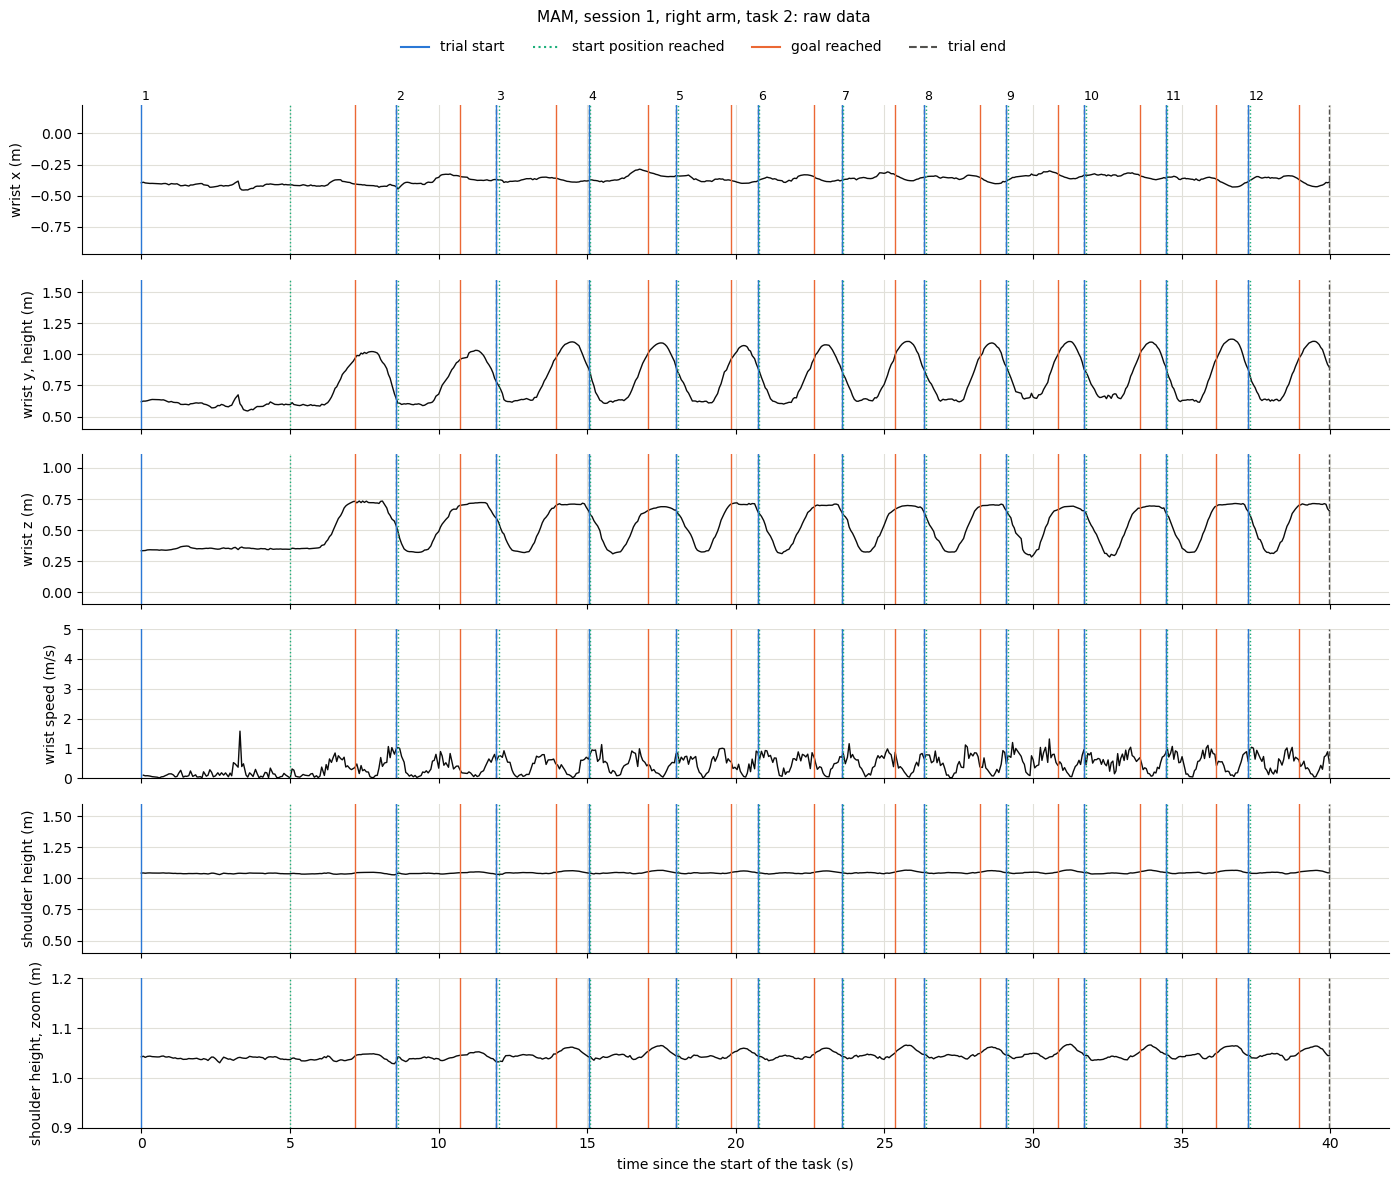

In [5]:
# Colour and line style of each stamp, as written in the events file.
STAMPS = {"trial_start": ("#2a78d6", "-", "trial start"), "trial_start_pose_locked": ("#1baf7a", ":", "start position reached"),
          "goal": ("#eb6834", "-", "goal reached"), "trial_end": ("#52514e", "--", "trial end")}
stamps = [("goal" if e["type"] in GOAL_EVENTS else e["type"], e["wall_time"] - start_time) for e in task_events]

# The same scale in every plot: all patients, pre and post, tasks and arms.
SPAN_M = 1.2          # every panel in metres covers this many metres
HEIGHT_M = (0.4, 1.6)  # wrist and shoulder height
SPEED_MS = (0, 5)
SHOULDER_ZOOM_M = (0.9, 1.2)   # smaller scale, to see the shoulder lifting

rows = [(frames[wrist[0]], "wrist x (m)", None), (frames[wrist[1]], "wrist y, height (m)", HEIGHT_M),
        (frames[wrist[2]], "wrist z (m)", None), (speed, "wrist speed (m/s)", SPEED_MS),
        (frames[shoulder[1]], "shoulder height (m)", HEIGHT_M),
        (frames[shoulder[1]], "shoulder height, zoom (m)", SHOULDER_ZOOM_M)]
fig, axes = plt.subplots(len(rows), 1, figsize=(14, 12), sharex=True)
for ax, (values, label, limits) in zip(axes, rows):
    middle = (values.min() + values.max()) / 2   # x and z: the same span, around where the wrist is in the room
    low, high = limits or (middle - SPAN_M / 2, middle + SPAN_M / 2)
    ax.plot(time, values, color="#0b0b0b", linewidth=1)
    ax.set_ylim(low, high)
    ax.set_ylabel(label)
    outside = ((values < low) | (values > high)).sum()
    if outside:
        print(f"{label}: {outside} frames outside the plotted range")
    ax.grid(color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    for kind, stamp in stamps:
        if kind in STAMPS:
            colour, style, _ = STAMPS[kind]
            ax.axvline(stamp, color=colour, linestyle=style, linewidth=1)
axes[-1].set_xlabel("time since the start of the task (s)")
for e in task_events:
    if e["type"] == "trial_start":
        axes[0].text(e["wall_time"] - start_time, 1.03, e["trial_index"], transform=axes[0].get_xaxis_transform(), fontsize=9)

fig.legend(handles=[Line2D([], [], color=colour, linestyle=style, label=label) for colour, style, label in STAMPS.values()],
           loc="upper center", ncols=4, frameon=False, bbox_to_anchor=(0.5, 0.965))
fig.suptitle(f"{PATIENT}, session {SESSION}, {SIDE} arm, task {TASK_ID}: raw data", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.95))